In [1]:
#Load the results from GitHub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = (
    "https://raw.githubusercontent.com/"
    "tran04012006/4_STAT3013_R11"
)

OUTPUT_DIR = Path("comparison_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

PHASES = [
    "pre_1_3", "during", "post_1_3",
    "post_4_7", "other"
]

MODELS = [
    "DLinear", "NLinear", "XGBoost",
    "LightGBM", "LSTM"
]

# Choose one variant per model where available
NLINEAR_VARIANT = "NLinear-X (KM + lich tuong lai)"
LIGHTGBM_VARIANT = "B_full_future"

def read_repo_csv(branch, path):
    url = f"{BASE}/{branch}/{path}"
    print("Reading:", url)
    return pd.read_csv(url)

# NLinear
N_BASE = "NLinear_Tien/outputs/metrics"

n_overall = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/overall.csv"
)
n_category = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/by_category.csv"
)
n_phase = read_repo_csv(
    "nlinear_forecasting", f"{N_BASE}/by_phase.csv"
)

# LightGBM
L_BASE = "1_model/tables"

l_overall = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/metrics_overall.csv"
)
l_category = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/overall_by_category.csv"
)
l_phase = read_repo_csv(
    "Hoang_LightGBM_GridSearch",
    f"{L_BASE}/metrics_by_segment.csv"
)

# LSTM
S_BASE = "output/lstm"

s_overall = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_overall.csv"
)
s_category = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_by_category.csv"
)
s_phase = read_repo_csv(
    "LSTM_GridSearch",
    f"{S_BASE}/metrics_test_by_phase.csv"
)

print("All available metric CSVs loaded.")


Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/by_category.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/nlinear_forecasting/NLinear_Tien/outputs/metrics/by_phase.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/metrics_overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/overall_by_category.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/Hoang_LightGBM_GridSearch/1_model/tables/metrics_by_segment.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/LSTM_GridSearch/output/lstm/metrics_test_overall.csv
Reading: https://raw.githubusercontent.com/tran04012006/4_STAT3013_R11/L

In [2]:
#Create standardized comparison tables

def pct(x):
    """Convert a WAPE ratio into a percentage."""
    return float(x) * 100

def result(model, mae, rmse, wape, source, n=np.nan):
    return {
        "Model": model,
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "N": n,
        "Source": source
    }

# -------------------------------
# OVERALL
# -------------------------------
rows = []

# DLinear: notebook output
rows.append(result(
    "DLinear", 2.638912, 12.045061, 59.884319,
    "DLinear notebook", 1101240
))

# NLinear
r = n_overall.query("model == @NLINEAR_VARIANT").iloc[0]
rows.append(result(
    "NLinear", r.MAE, r.RMSE, pct(r.WAPE),
    "GitHub test CSV", r.n
))

# XGBoost: Tweedie 1.2 test results from slide
rows.append(result(
    "XGBoost", 2.627, 12.056, 58.7,
    "Presentation test results", 177713
))

# LightGBM: TEST only
r = l_overall[
    (l_overall["split"] == "test") &
    (l_overall["model"] == LIGHTGBM_VARIANT)
].iloc[0]
rows.append(result(
    "LightGBM", r.MAE, r.RMSE, pct(r.WAPE),
    "GitHub test CSV", r.n
))

# LSTM
r = s_overall.iloc[0]
rows.append(result(
    "LSTM", r.lstm_MAE, r.lstm_RMSE,
    pct(r.lstm_WAPE),
    "GitHub test CSV", r.n
))

overall = pd.DataFrame(rows).set_index("Model")
overall = overall.reindex(MODELS)

# -------------------------------
# CATEGORY
# -------------------------------
category_rows = []

def add_category(model, cat, wape, source):
    category_rows.append({
        "Model": model,
        "Category": cat,
        "WAPE": float(wape),
        "Source": source
    })

# DLinear: presentation results
for cat, value in [
    ("food", 55.5901),
    ("household", 91.0730)
]:
    add_category("DLinear", cat, value, "Presentation")

# XGBoost: Tweedie 1.2 results
for cat, value in [
    ("food", 55.4),
    ("household", 83.8)
]:
    add_category("XGBoost", cat, value, "Presentation")

# NLinear
for _, r in n_category[
    n_category["model"] == NLINEAR_VARIANT
].iterrows():
    add_category(
        "NLinear", r["category"],
        pct(r["WAPE"]), "GitHub"
    )

# LightGBM: use test_WAPE
for _, r in l_category[
    l_category["model"] == LIGHTGBM_VARIANT
].iterrows():
    add_category(
        "LightGBM", r["category"],
        pct(r["test_WAPE"]), "GitHub"
    )

# LSTM
for _, r in s_category.iterrows():
    add_category(
        "LSTM", r["category"],
        pct(r["lstm_WAPE"]), "GitHub"
    )

category = pd.DataFrame(category_rows)

# -------------------------------
# PROMOTION PHASES
# -------------------------------
phase_rows = []

def add_phase(model, phase, mae, wape, source):
    phase_rows.append({
        "Model": model,
        "Phase": phase,
        "MAE": float(mae),
        "WAPE": float(wape),
        "Source": source
    })

# DLinear: screenshot results
d_mae = [1.9519, 2.8718, 3.3165, 3.0637, 2.5771]
d_wape = [79.1808, 57.6775, 69.8418, 78.4565, 58.7583]

for p, mae, wape in zip(PHASES, d_mae, d_wape):
    add_phase("DLinear", p, mae, wape, "Presentation")

# XGBoost: best variant PER PHASE from presentation
# These rows are not one fixed XGBoost checkpoint.
x_mae = [1.730, 2.857, 2.762, 2.317, 2.625]
x_wape = [68.74, 56.50, 58.60, 58.98, 58.85]

for p, mae, wape in zip(PHASES, x_mae, x_wape):
    add_phase(
        "XGBoost", p, mae, wape,
        "Presentation (phase-best variants)"
    )

# NLinear
for _, r in n_phase[
    n_phase["model"] == NLINEAR_VARIANT
].iterrows():
    add_phase(
        "NLinear", r["phase"],
        r["MAE"], pct(r["WAPE"]), "GitHub"
    )

# LightGBM
for _, r in l_phase[
    (l_phase["segment"] == "phase") &
    (l_phase["model"] == LIGHTGBM_VARIANT)
].iterrows():
    add_phase(
        "LightGBM", r["value"],
        r["MAE"], pct(r["WAPE"]), "GitHub"
    )

# LSTM
for _, r in s_phase.iterrows():
    add_phase(
        "LSTM", r["phase"],
        r["lstm_MAE"],
        pct(r["lstm_WAPE"]), "GitHub"
    )

phase = pd.DataFrame(phase_rows)

print("OVERALL METRICS")
display(overall.round(3))

print("CATEGORY METRICS")
display(category.pivot(
    index="Model",
    columns="Category",
    values="WAPE"
).reindex(MODELS).round(2))

print("PHASE METRICS")
display(phase.head())


OVERALL METRICS


,MAE,RMSE,WAPE,N,Source
Model,,,,,
DLinear,2.639,12.045,59.884,1101240.0,DLinear notebook
NLinear,2.524,11.781,56.410,177713.0,GitHub test CSV
XGBoost,2.627,12.056,58.700,177713.0,Presentation test results
LightGBM,2.562,11.911,57.253,177713.0,GitHub test CSV
LSTM,2.432,12.215,54.352,177713.0,GitHub test CSV


CATEGORY METRICS


Category,food,household
Model,,
DLinear,55.59,91.07
NLinear,53.26,79.91
XGBoost,55.40,83.80
LightGBM,54.01,81.45
LSTM,51.63,74.67


PHASE METRICS


,Model,Phase,MAE,WAPE,Source
0,DLinear,pre_1_3,1.9519,79.1808,Presentation
1,DLinear,during,2.8718,57.6775,Presentation
2,DLinear,post_1_3,3.3165,69.8418,Presentation
3,DLinear,post_4_7,3.0637,78.4565,Presentation
4,DLinear,other,2.5771,58.7583,Presentation


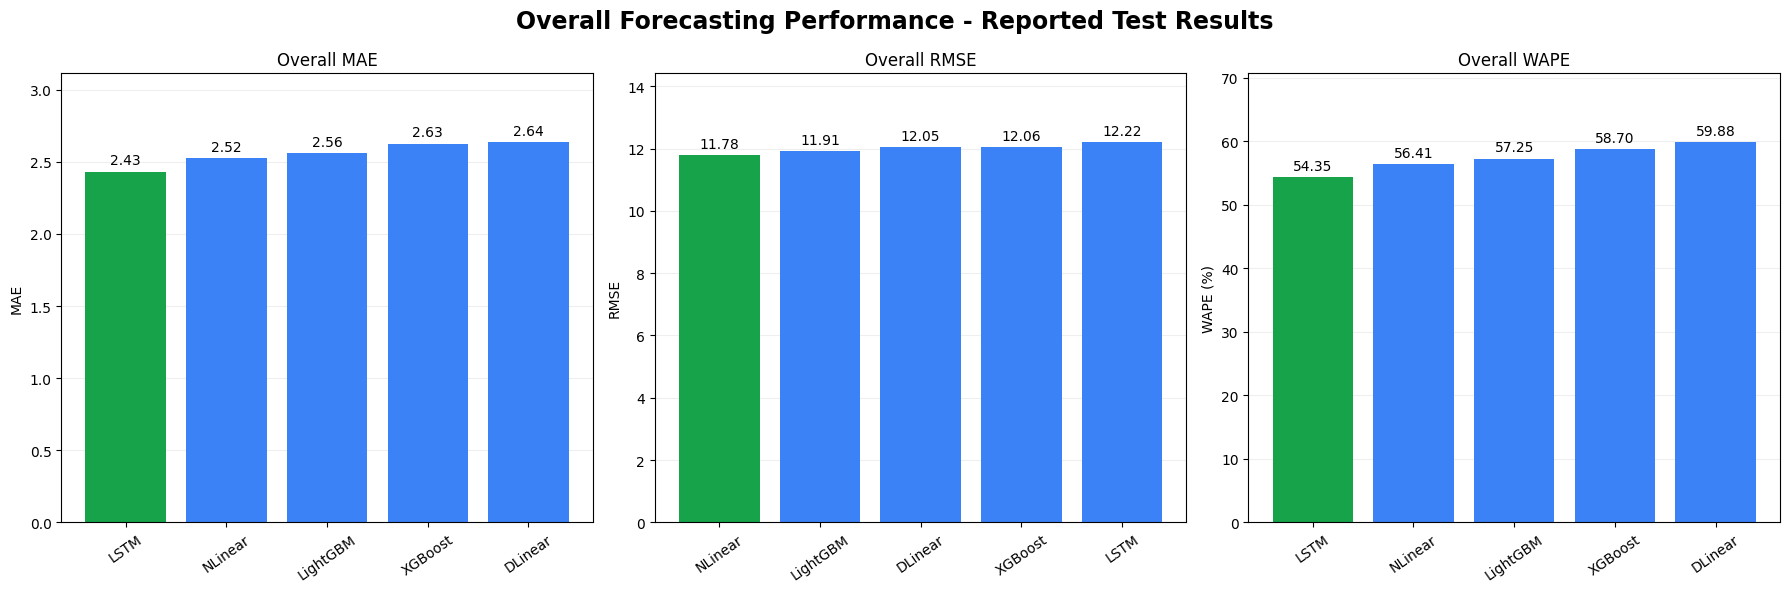

In [3]:
#Visualize overall MAE, RMSE, WAPE

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(
    axes, ["MAE", "RMSE", "WAPE"]
):
    values = overall[metric].sort_values()

    colors = [
        "#16A34A" if model == values.index[0]
        else "#3B82F6"
        for model in values.index
    ]

    bars = ax.bar(
        values.index, values.values,
        color=colors
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(f"Overall {metric}")
    ax.set_ylabel(
        metric + (" (%)" if metric == "WAPE" else "")
    )
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Overall Forecasting Performance - Reported Test Results",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "01_overall_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


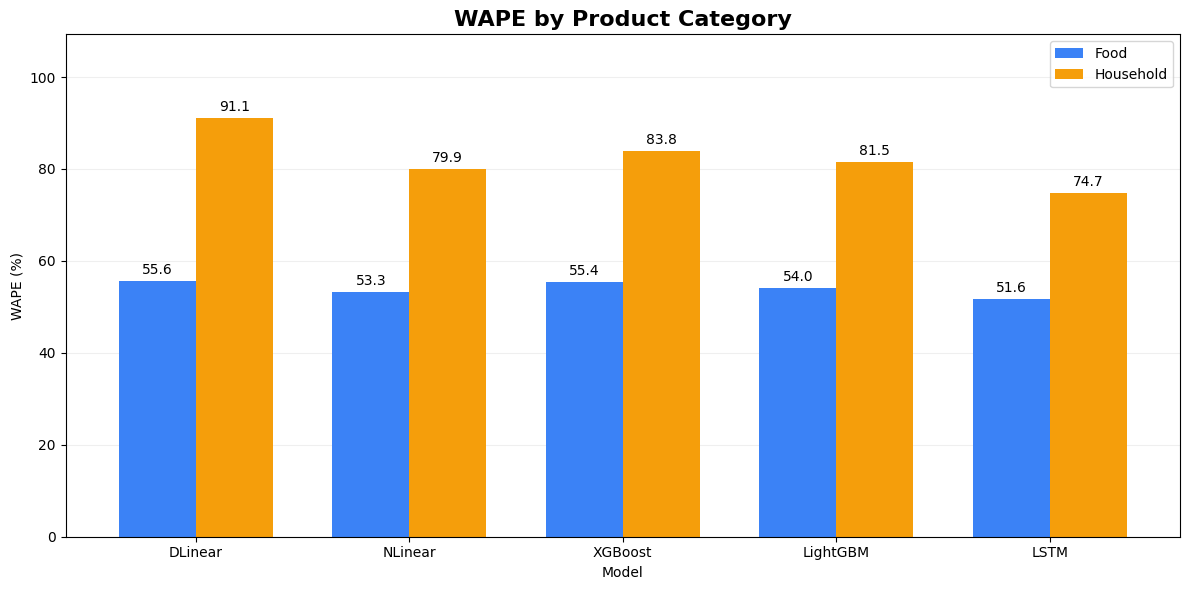

In [4]:
#Visualize Food vs Household WAPE

cat_plot = category.pivot(
    index="Model",
    columns="Category",
    values="WAPE"
).reindex(MODELS)

ax = cat_plot[["food", "household"]].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.72,
    color=["#3B82F6", "#F59E0B"]
)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3)

ax.set_title(
    "WAPE by Product Category",
    fontsize=16, fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("WAPE (%)")
ax.set_xticklabels(MODELS, rotation=0)
ax.legend(["Food", "Household"])
ax.set_ylim(0, cat_plot.max().max() * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "02_category_wape.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


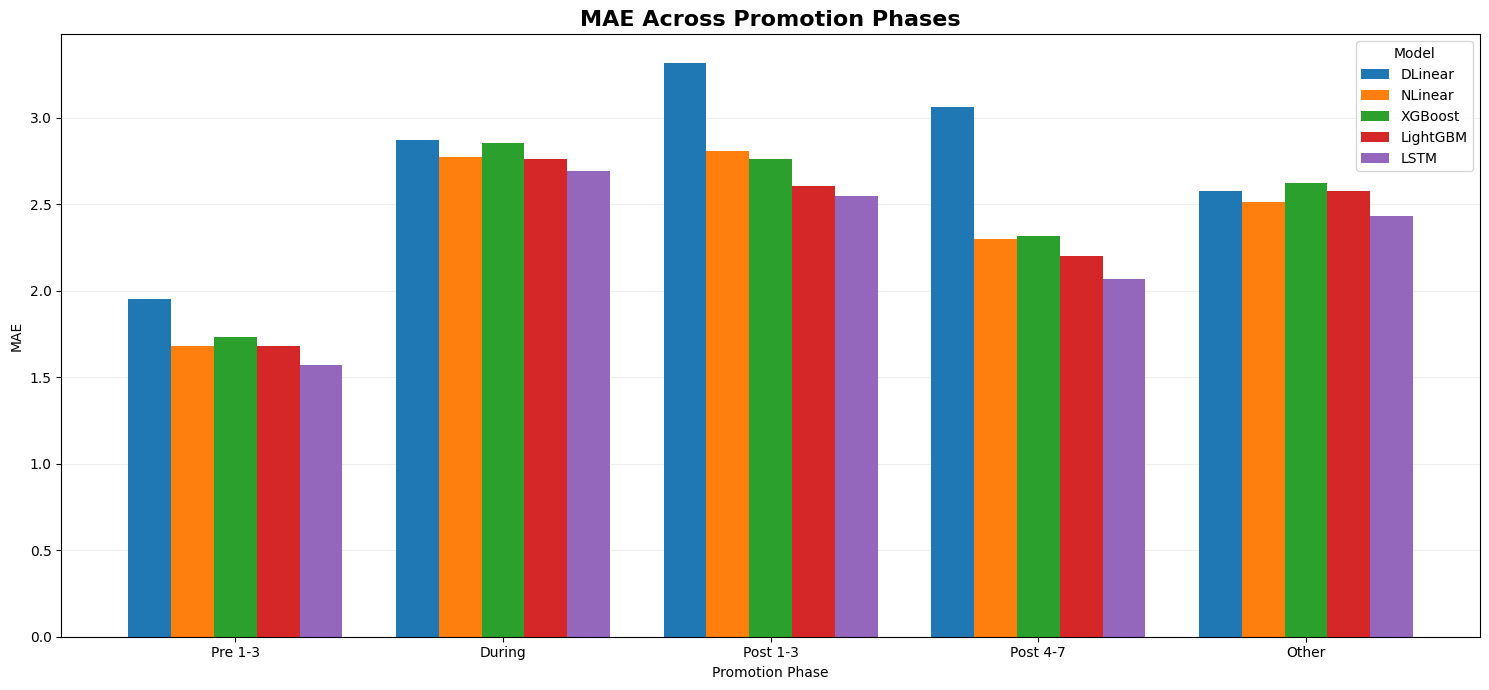

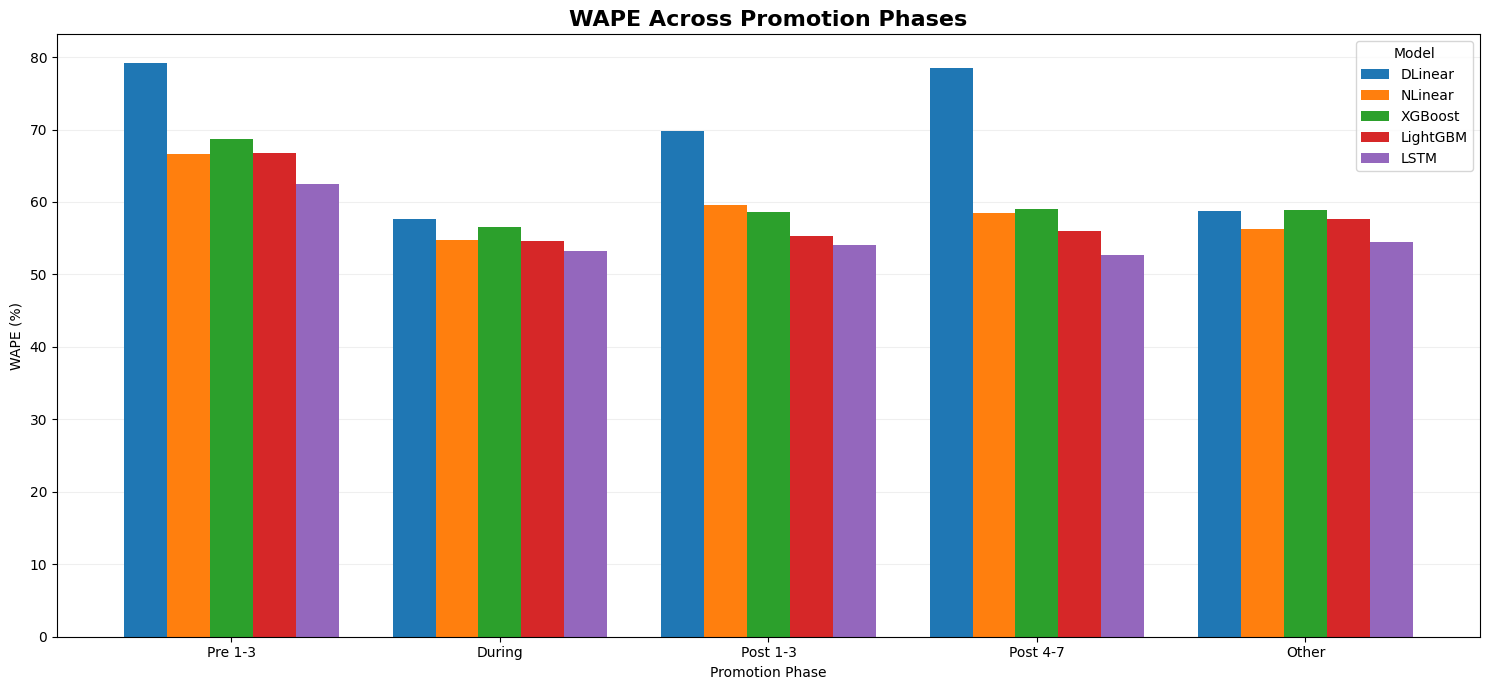

In [5]:
#Visualize MAE and WAPE across promotion phases

phase_labels = {
    "pre_1_3": "Pre 1-3",
    "during": "During",
    "post_1_3": "Post 1-3",
    "post_4_7": "Post 4-7",
    "other": "Other"
}

for metric in ["MAE", "WAPE"]:
    plot_data = phase.pivot(
        index="Phase",
        columns="Model",
        values=metric
    )

    plot_data = plot_data.reindex(
        index=PHASES,
        columns=MODELS
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(15, 7),
        width=0.8
    )

    ax.set_xticklabels(
        [phase_labels[p] for p in PHASES],
        rotation=0
    )
    ax.set_title(
        f"{metric} Across Promotion Phases",
        fontsize=16,
        fontweight="bold"
    )
    ax.set_xlabel("Promotion Phase")
    ax.set_ylabel(
        metric + (" (%)" if metric == "WAPE" else "")
    )
    ax.legend(title="Model", bbox_to_anchor=(1, 1))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"03_phase_{metric.lower()}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()


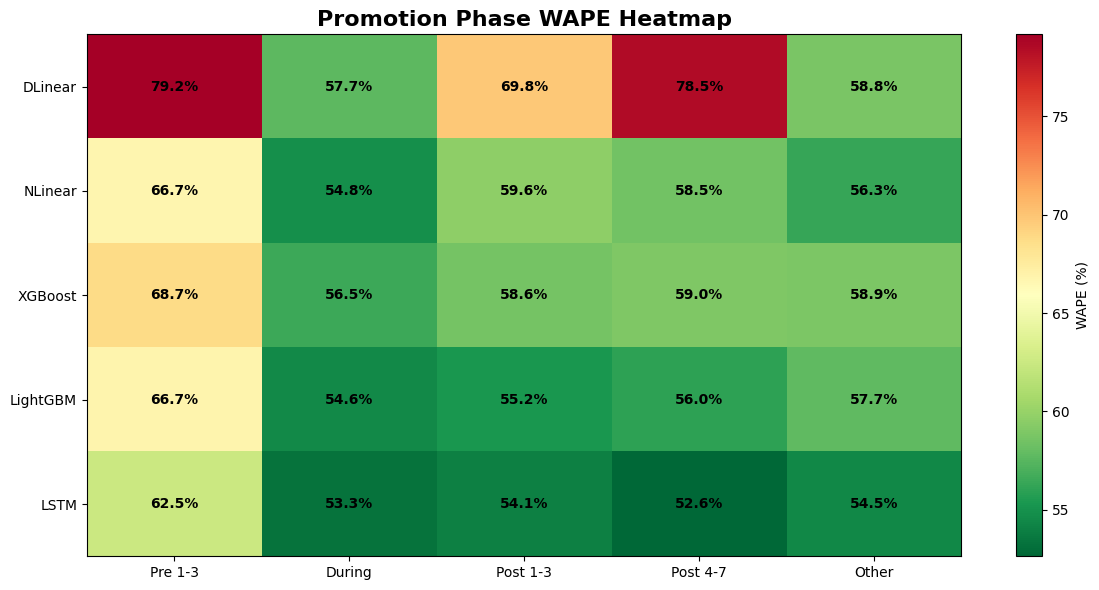

In [6]:
#Create a heatmap for promotion phases

plot_data = phase.pivot(
    index="Model",
    columns="Phase",
    values="WAPE"
).reindex(index=MODELS, columns=PHASES)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    plot_data.values,
    cmap="RdYlGn_r",
    aspect="auto"
)

ax.set_xticks(range(len(PHASES)))
ax.set_xticklabels([phase_labels[p] for p in PHASES])

ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(MODELS)

for i in range(len(MODELS)):
    for j in range(len(PHASES)):
        value = plot_data.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                fontweight="bold"
            )

fig.colorbar(im, ax=ax, label="WAPE (%)")

ax.set_title(
    "Promotion Phase WAPE Heatmap",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "04_phase_heatmap.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [7]:
#Automatically summarize the reported winners

def print_winner(df, metric):
    values = df[metric].dropna()
    winner = values.idxmin()
    return winner, values.min()

print("=== OVERALL ===")
for metric in ["MAE", "RMSE", "WAPE"]:
    winner, score = print_winner(overall, metric)
    print(f"{metric}: {winner} ({score:.3f})")

print("\n=== BY CATEGORY ===")
for cat in ["food", "household"]:
    subset = category[category["Category"] == cat]
    best = subset.loc[subset["WAPE"].idxmin()]
    print(
        f"{cat}: {best['Model']} "
        f"(WAPE = {best['WAPE']:.2f}%)"
    )

print("\n=== BY PROMOTION PHASE ===")
for p in PHASES:
    subset = phase[phase["Phase"] == p]

    for metric in ["MAE", "WAPE"]:
        best = subset.loc[subset[metric].idxmin()]
        print(
            f"{p} | {metric}: {best['Model']} "
            f"({best[metric]:.2f})"
        )

# Export the complete comparison tables
overall.to_csv(OUTPUT_DIR / "overall.csv")
category.to_csv(
    OUTPUT_DIR / "category.csv", index=False
)
phase.to_csv(
    OUTPUT_DIR / "phase.csv", index=False
)

print("\nAll figures and tables saved to:", OUTPUT_DIR)


=== OVERALL ===
MAE: LSTM (2.432)
RMSE: NLinear (11.781)
WAPE: LSTM (54.352)

=== BY CATEGORY ===
food: LSTM (WAPE = 51.63%)
household: LSTM (WAPE = 74.67%)

=== BY PROMOTION PHASE ===
pre_1_3 | MAE: LSTM (1.57)
pre_1_3 | WAPE: LSTM (62.53)
during | MAE: LSTM (2.69)
during | WAPE: LSTM (53.29)
post_1_3 | MAE: LSTM (2.55)
post_1_3 | WAPE: LSTM (54.05)
post_4_7 | MAE: LSTM (2.07)
post_4_7 | WAPE: LSTM (52.62)
other | MAE: LSTM (2.43)
other | WAPE: LSTM (54.48)

All figures and tables saved to: comparison_figures
